In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from math import floor, ceil

# Задание 1. Изменение размера изображения

In [2]:
img_path = "../data/small_img.png"
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

error: OpenCV(4.13.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


In [ ]:
h, w = img.shape[:2]
dpi = 100

plt.figure(figsize=(w/dpi, h/dpi), dpi=dpi)
plt.imshow(img)
plt.axis('off')
plt.show()

In [ ]:
img.shape[:2]

In [ ]:
def new_to_old_cords(new_cords, a, b):
    return new_cords * a + b

def find_ab(old_size, new_size):
    Ax = np.array([
        [-.5, 1],
        [new_size[0] - 0.5, 1]
    ])
    bx = np.array([-.5, old_size[0] - .5])

    Ay = np.array([
        [-.5, 1],
        [new_size[1] - 0.5, 1]
    ])
    by = np.array([-.5, old_size[1] -.5])

    a1, b1 = np.linalg.solve(Ax, bx)
    a2, b2 = np.linalg.solve(Ay, by)
    return np.array([a1, a2]), np.array([b1, b2])

In [ ]:
a, b = find_ab([4, 4], [7, 7])
new_to_old_cords([1, 3], a, b)

In [ ]:
def resize_nn(img, size_factor):
    h, w = img.shape[:2]
    new_h, new_w = (np.array(img.shape[:2], dtype='float') * size_factor).round()
    old_size = [h, w]
    new_size = [new_h, new_w]
    enlarged_img = np.zeros((int(new_h), int(new_w), 3), dtype='uint8')
    
    a, b = find_ab(old_size, new_size)
    
    for i in range(int(new_h)):
        for j in range(int(new_w)):
            old_x, old_y = new_to_old_cords([i, j], a, b)
            enlarged_img[i, j, :] = img[int(round(old_x, 0)), int(round(old_y, 0)), :]
    return enlarged_img

In [ ]:
def resize_bilinear(img, size_factor):
    padded_img = np.pad(img, 
                    ((1, 1), (1, 1), (0, 0)), 
                    mode='edge')
    
    h, w = img.shape[:2]
    new_h, new_w = (np.array(img.shape[:2], dtype='float') * size_factor).round()
    old_size = [h, w]
    new_size = [new_h, new_w]
    enlarged_img = np.zeros((int(new_h), int(new_w), 3), dtype='uint8')
    
    a, b = find_ab(old_size, new_size)
    
    for i in range(int(new_h)):
        for j in range(int(new_w)):
            old_x, old_y = new_to_old_cords([i, j], a, b)
            v1 = np.array([floor(old_x), floor(old_y)])
            v2 = np.array([floor(old_x), ceil(old_y)])
            v3 = np.array([ceil(old_x), floor(old_y)])
            v4 = np.array([ceil(old_x), ceil(old_y)])

            d1 = old_y - v1[1]
            d2 = v2[1] - old_y
            d3 = old_x - v2[0]
            d4 = v4[0] - old_x

            q = padded_img[*v1, :]*d2*d4 + padded_img[*v2, :]*d1*d4 + padded_img[*v3, :]*d2*d3 + padded_img[*v4, :]*d1*d3
            enlarged_img[i, j, :] = q
    return enlarged_img

In [ ]:
resize_factor = 10
enlarged_img_nn = resize_nn(img, resize_factor)
enlarged_img_bilinear = resize_bilinear(img, resize_factor)
enlarged_imgs = [enlarged_img_nn, enlarged_img_bilinear]

In [ ]:
h, w = enlarged_img_nn.shape[:2]
dpi = 100

titles = ['nn', 'bilinear']
fig, axes = plt.subplots(1, 2, figsize=(2*w/dpi, 4 * h/dpi))
for i in range(2):
    axes[i].imshow(enlarged_imgs[i])
    axes[i].set_title(titles[i])
    axes[i].axis('off')

# Задание 2. Сжатие изображения

In [ ]:
def downsample_1(img, size_factor):
    h, w = img.shape[:2]
    print(f"Исходный размер: {h} {w}")

    if h % size_factor != 0:
        pad_h = size_factor * (h // size_factor + 1) - h
    else: 
        pad_h = 0


    if w % size_factor != 0:
        pad_w = size_factor * (w // size_factor + 1) - w
    else:
        pad_w = 0

    print(pad_h, pad_w)
    
    padded_img = np.pad(img, 
                    ((0, pad_h), (0, pad_w), (0, 0)), 
                    mode='edge')
    
    print(f"Размер с паддингом: {padded_img.shape}")
    new_h, new_w = map(int, np.array(padded_img.shape[:2]) / size_factor)
    old_size = [h, w]
    new_size = [new_h, new_w]
    thumbnail_img = np.zeros((int(new_h), int(new_w), 3), dtype='uint8')
    print(f"Размеры уменьшенного изображения: {thumbnail_img.shape}")

    for i in range(thumbnail_img.shape[0]):
        for j in range(thumbnail_img.shape[1]):
            thumbnail_img[i, j, :] = padded_img[i*size_factor + size_factor//2, j*size_factor + size_factor//2, :]
    
    
    return thumbnail_img

In [ ]:
def downsample_2(img, size_factor):
    h, w = img.shape[:2]

    if h % size_factor != 0:
        pad_h = size_factor * (h // size_factor + 1) - h
    else: 
        pad_h = 0


    if w % size_factor != 0:
        pad_w = size_factor * (w // size_factor + 1) - w
    else:
        pad_w = 0

    print(pad_h, pad_w)
    
    padded_img = np.pad(img, 
                    ((0, pad_h), (0, pad_w), (0, 0)), 
                    mode='edge')
    
    new_h, new_w = map(int, np.array(padded_img.shape[:2]) / size_factor)
    old_size = [h, w]
    new_size = [new_h, new_w]
    thumbnail_img = np.zeros((int(new_h), int(new_w), 3), dtype='uint8')

    for i in range(thumbnail_img.shape[0]):
        for j in range(thumbnail_img.shape[1]):
            thumbnail_img[i, j, :] = padded_img[i*size_factor : size_factor*(i+1), j*size_factor : size_factor*(j + 1), :].mean(axis=(0, 1))
    
    
    return thumbnail_img

In [ ]:
img_path2 = "../data/Lenna.png"
img2 = cv2.imread(img_path2)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

In [ ]:
scale = 10
ds1 = downsample_1(img2, scale)
ds2 = downsample_2(img2, scale)

In [ ]:
plt.figure(figsize=(15, 5))
plt.title(f'Уменьшение изображения в {scale} раз')
plt.axis('off')

plt.subplot(1, 3, 1)
plt.imshow(img2)
plt.axis('off')
plt.title('Исходное')

plt.subplot(1, 3, 2)
plt.imshow(ds1)
plt.axis('off')
plt.title('nn')

plt.subplot(1, 3, 3)
plt.imshow(ds2)
plt.axis('off')
plt.title('avg')
plt.show()

# Задание 3. Изменение яркости

In [100]:
path = '../data/images/photo1.jpg'
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

In [101]:
def draw_img_hist(img, title=None):
    values = np.arange(256)
    counts = np.bincount(img.ravel(), minlength=256)
    plt.figure(figsize=(12, 5))
    plt.title(title)
    plt.axis('off')
    
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Изображение', fontsize=8)
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.plot(values, counts, color='black', lw=1)
    plt.title('Гистограмма', fontsize=8)
    plt.xlim([0, 255])
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.fill_between(values, counts, color='gray', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

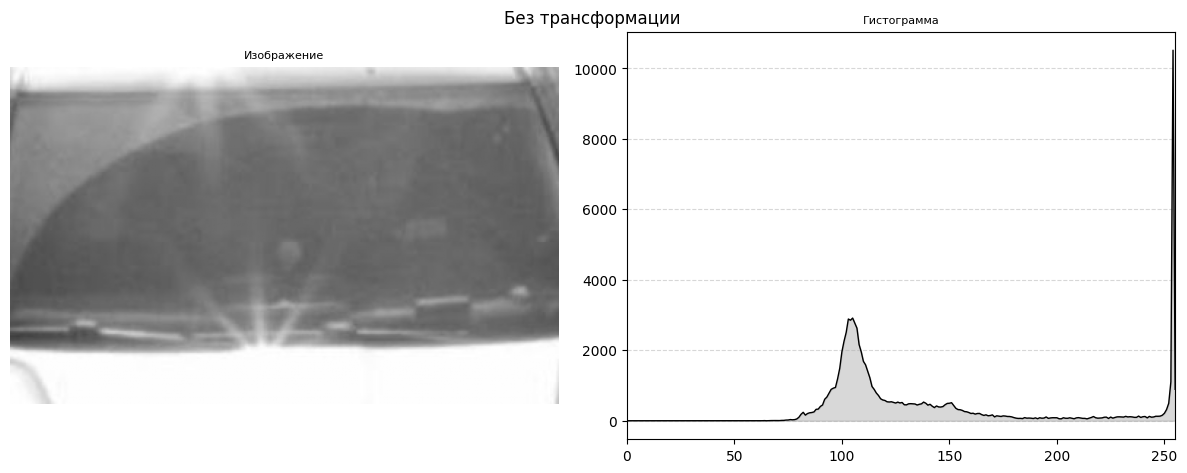

In [102]:
draw_img_hist(img, 'Без трансформации')

In [103]:
def linear_hist_transform(img, persent=0.05):
    low = np.percentile(img, persent*100)
    high = np.percentile(img, 100 - persent*100)

    clipped = np.clip(img, low, high)
    transform_img = 255 * ((clipped - clipped.min()) / (clipped.max() - clipped.min()))
    transform_img = transform_img.astype('uint8')
    return transform_img

In [104]:
tr_img = linear_hist_transform(img, persent=0.1)

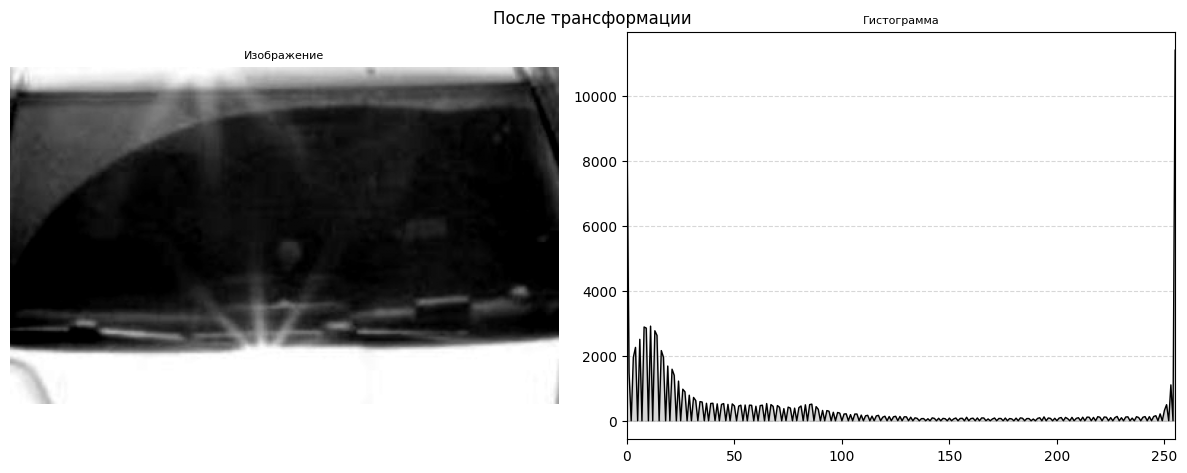

In [105]:
draw_img_hist(tr_img, 'После трансформации')

# Задание 4. Гамма-коррекция

In [106]:
def gamma_transform(img, gamma):
    transform_img = (img - img.min()) / (img.max() - img.min())
    transform_img = 255 * transform_img ** gamma
    transform_img = transform_img.astype('uint8')
    return transform_img

In [107]:
gamma = np.arange(0.1, 3, 0.1).round(1)
gamma_imgs = [gamma_transform(img, g) for g in gamma]

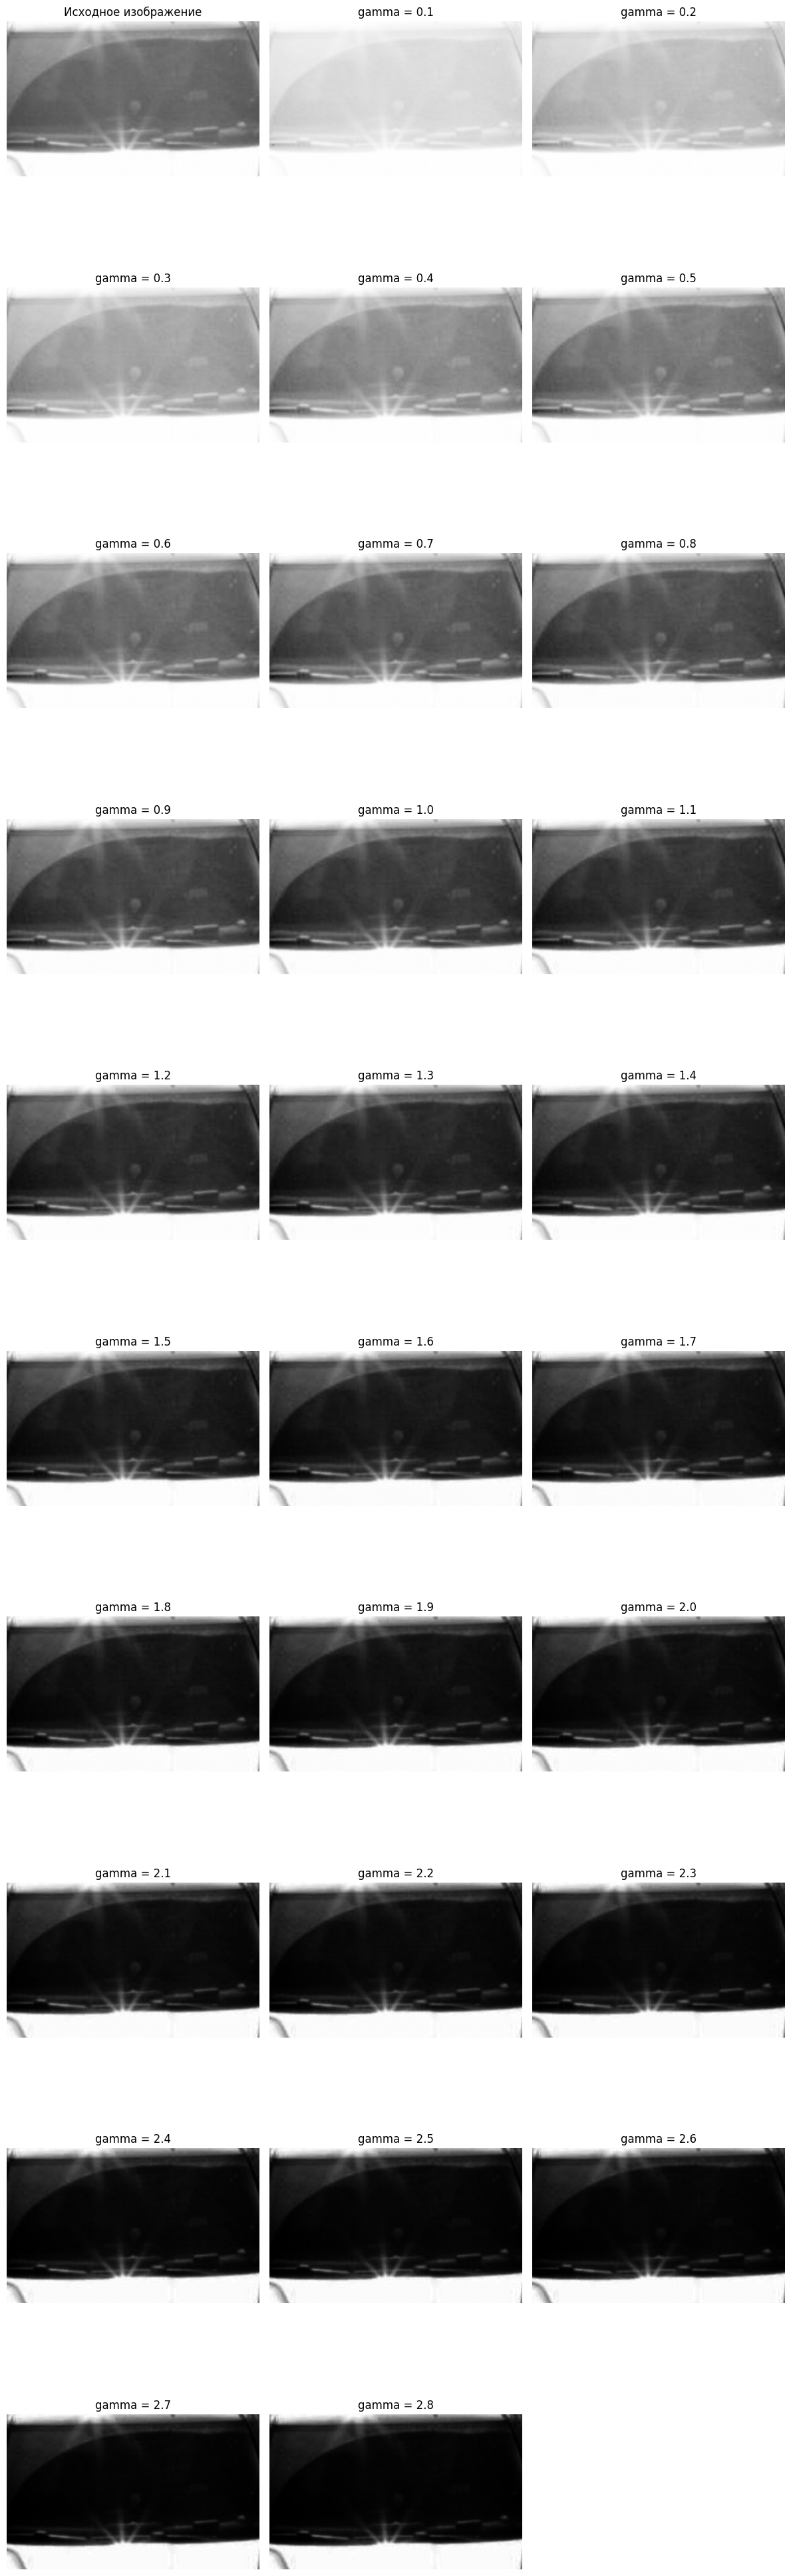

In [108]:
cols = 3
rows = ceil(len(gamma) + 1 / cols)

fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = axes.flatten()

for i in range(0, len(gamma)+1):
    ax = axes[i]
    if i != 0:
        ax.imshow(gamma_imgs[i-1], cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        ax.set_title(f'gamma = {gamma[i-1]}')
    else:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        ax.set_title(f'Исходное изображение')

for i in range(len(gamma_imgs), len(axes)):
    axes[i].set_visible(False)
    
fig.tight_layout()

# Задание 5. Эквализация гистограммы

In [109]:
def hist_eq(img):
    count = np.bincount(img.ravel(), minlength=256)
    p = count / sum(count)
    transform_img = img.copy()
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            transform_img[i][j] = floor(255 * sum(p[:img[i][j]]))
    transform_img = transform_img.astype('uint8')
    return transform_img

In [110]:
eq_hist_img = hist_eq(img)

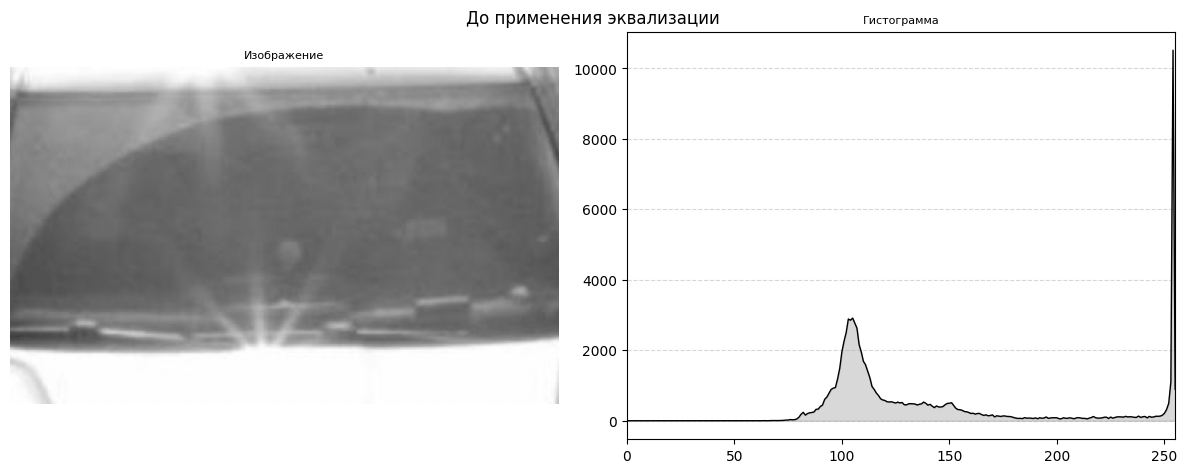

In [111]:
draw_img_hist(img, 'До применения эквализации')

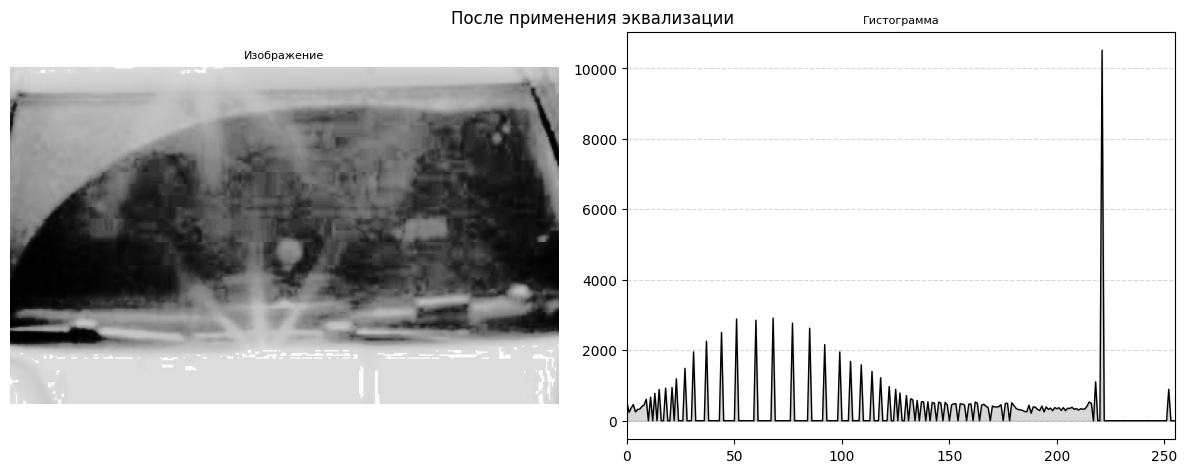

In [112]:
draw_img_hist(eq_hist_img, 'После применения эквализации')